# 07 — How much history should Chronos-2 read?

Out of the box, Chronos-2 reads the whole history of every series (notebook 05). The context length is the
one setting that decides how much of it the model sees: it reads the last `context_length` days and ignores
the rest. More is not automatically better: a long context can dilute the recent behaviour that drives the
next few days, while the far horizon may need more of the past.

**Method.** Forecast the validation window with a grid of context lengths and score each one **by horizon
bucket**. In the main figure, x is the horizon bucket and the color is the context length: if one length is
best for the first week and another for the following weeks, their lines cross, which a single overall score
cannot show. Two passes: a coarse grid over the whole legal range, then a fine grid (one-week steps) around
the winners.

**Decision rule, fixed before looking.** For the first week (days 1–7) and for the rest (days 8–28)
separately, keep the context length with the lowest **WQL** (the score of the whole forecast distribution,
and the loss Chronos-2 was trained on). If the two winners differ, *stitch*: take days 1–7 from one, days
8–28 from the other. The boundary is the edge of the first horizon bucket, not a tuned value.

Validation window only: the test window is used once, in notebook 08.

In [1]:
%load_ext autoreload
%autoreload 2

import json

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from m5_chronos2.data import ARTIFACTS_DIR, roster_name
from m5_chronos2.evaluation import actuals, make_windows
from m5_chronos2.metrics import METRICS, compare, join_truth, score
from m5_chronos2.chronos2 import cached, experiment_path, forecast, history, stitch
from m5_chronos2.plots import MAIN_COLOR, MUTED_TEXT_COLOR, TEXT_COLOR, plot_context_sweep, use_blog_style

use_blog_style()

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42
NAME = roster_name(SAMPLE_SIZE, SEED)
DEVICE = "cpu"

# Coarse grid, in days: from one week to the longest history, roughly evenly spaced on a log scale.
COARSE_GRID = [7, 14, 21, 28, 42, 56, 84, 112, 140, 168, 224, 280, 364, 448, 560, 728, 896, 1092, 1288, 1456, 1680]
FINE_STEP = 7          # fine grid: one-week steps...
FINE_HALF_WIDTH = 56   # ... within 8 weeks of each winner
SELECTION_METRIC = "WQL"
EARLY_LAST_DAY = 7     # days 1-7 vs days 8-28: the edge of the first horizon bucket
PLATEAU = 0.01         # lengths within 1% of the best score are reported as equivalent

In [3]:
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
truth = actuals(sales)
windows = make_windows()
VALIDATION_ORIGIN = windows.filter(pl.col("role") == "validation")["origin"][0]
validation_roster = pl.read_parquet(ARTIFACTS_DIR / f"eval_roster_{NAME}.parquet").filter(pl.col("role") == "validation")

context = history(sales, VALIDATION_ORIGIN)
MAX_HISTORY = context.group_by("id").len()["len"].max()
print(f"Longest history at the validation origin: {MAX_HISTORY} days")
# Any context length at or above MAX_HISTORY is the vanilla model: every series is read in full.
COARSE_GRID = sorted({length for length in COARSE_GRID if length < MAX_HISTORY} | {MAX_HISTORY})
print(f"Coarse grid ({len(COARSE_GRID)} lengths): {COARSE_GRID}")

Longest history at the validation origin: 1885 days
Coarse grid (22 lengths): [7, 14, 21, 28, 42, 56, 84, 112, 140, 168, 224, 280, 364, 448, 560, 728, 896, 1092, 1288, 1456, 1680, 1885]


One forecast per context length, saved to `artifacts/experiments/` (a few seconds to a minute each on a
laptop CPU, then read back on later runs).

In [4]:
def run_context(length):
    return cached(
        experiment_path(f"context_{length}", NAME),
        lambda: forecast(context, VALIDATION_ORIGIN, context_length=int(length), device=DEVICE),
    )


segment = pl.when(pl.col("horizon") <= EARLY_LAST_DAY).then(pl.lit("days 01-07")).otherwise(pl.lit("days 08-28"))


def sweep(lengths):
    # Scores of each context length: per horizon bucket, per segment (early / late), overall.
    by_bucket, by_segment, overall = [], [], []
    for length in lengths:
        scored = join_truth(run_context(length), truth, validation_roster)
        tag = pl.lit(length).alias("context_length")
        by_bucket.append(score(scored, by="horizon_bucket").with_columns(tag))
        by_segment.append(score(scored.with_columns(segment.alias("segment")), by="segment").with_columns(tag))
        overall.append(score(scored).with_columns(tag))
    return pl.concat(by_bucket), pl.concat(by_segment), pl.concat(overall)


def winners(by_segment, metric=SELECTION_METRIC):
    # Best context length per segment, and the lengths within PLATEAU of it.
    rows = []
    for name, part in by_segment.group_by("segment", maintain_order=True):
        best = part.sort(metric).row(0, named=True)
        plateau = part.filter(pl.col(metric) <= best[metric] * (1 + PLATEAU))["context_length"].sort().to_list()
        rows.append({"segment": name[0], "best_context": best["context_length"], metric: best[metric],
                     f"within {PLATEAU:.0%} of best": plateau})
    return pl.DataFrame(rows).sort("segment")

## 1. Coarse pass

In [5]:
coarse_bucket, coarse_segment, coarse_overall = sweep(COARSE_GRID)

/Users/amelien/Desktop/ML/BLOG/m5-chronos2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  computed context_7_n500_seed42.parquet in 20 s
  computed context_14_n500_seed42.parquet in 5 s
  computed context_21_n500_seed42.parquet in 7 s
  computed context_28_n500_seed42.parquet in 7 s
  computed context_42_n500_seed42.parquet in 8 s
  computed context_56_n500_seed42.parquet in 9 s
  computed context_84_n500_seed42.parquet in 15 s
  computed context_112_n500_seed42.parquet in 13 s
  computed context_140_n500_seed42.parquet in 14 s
  computed context_168_n500_seed42.parquet in 17 s
  computed context_224_n500_seed42.parquet in 21 s
  computed context_280_n500_seed42.parquet in 25 s
  computed context_364_n500_seed42.parquet in 31 s
  computed context_448_n500_seed42.parquet in 38 s
  computed context_560_n500_seed42.parquet in 46 s
  computed context_728_n500_seed42.parquet in 60 s
  computed context_896_n500_seed42.parquet in 82 s
  computed context_1092_n500_seed42.parquet in 93 s
  computed context_1288_n500_seed42.parquet in 110 s
  computed context_1456_n500_seed42.parqu

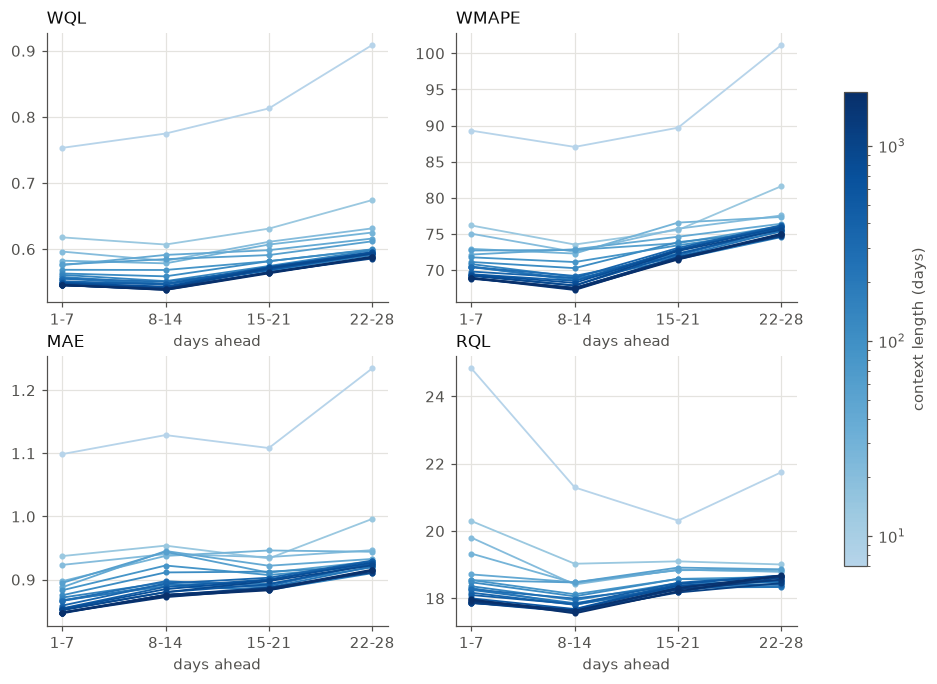

In [6]:
def plot_sweep(by_bucket, metrics=("WQL", "WMAPE", "MAE", "RQL")):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    mappable = plot_context_sweep(axes.ravel(), by_bucket, list(metrics))
    fig.colorbar(mappable, ax=axes, label="context length (days)", shrink=0.8)
    return fig

plot_sweep(coarse_bucket)
plt.show()

The same information read the other way: for each segment, the score of every context length relative to
the vanilla model (context = the whole history). Below 0: better than vanilla.

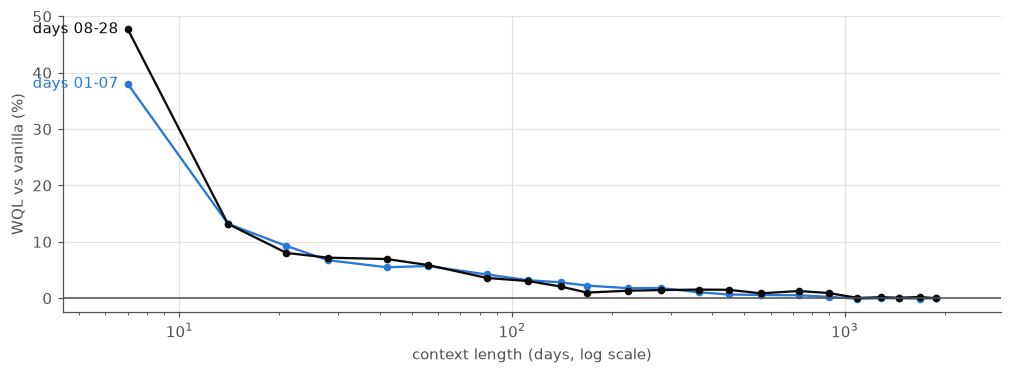

segment,best_context,WQL,within 1% of best
str,i64,f64,list[i64]
"""days 01-07""",1092,0.54516,"[448, 560, … 1885]"
"""days 08-28""",1885,0.562571,"[168, 560, … 1885]"


In [7]:
def plot_segments(by_segment, metric=SELECTION_METRIC):
    fig, ax = plt.subplots(figsize=(11, 3.5))
    for (name,), part in by_segment.group_by("segment", maintain_order=True):
        part = part.sort("context_length")
        vanilla_value = part.filter(pl.col("context_length") == MAX_HISTORY)[metric][0]
        relative = 100 * (part[metric].to_numpy() / vanilla_value - 1)
        color = MAIN_COLOR if name == "days 01-07" else TEXT_COLOR
        ax.plot(part["context_length"].to_numpy(), relative, color=color, marker="o", markersize=4, linewidth=1.5)
        ax.annotate(name, (part["context_length"][0], relative[0]), xytext=(-6, 0), textcoords="offset points",
                    ha="right", va="center", color=color)
    ax.axhline(0, color=MUTED_TEXT_COLOR, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("context length (days, log scale)")
    ax.set_ylabel(f"{metric} vs vanilla (%)")
    ax.margins(x=0.08)
    return fig

plot_segments(coarse_segment)
plt.show()
winners(coarse_segment)

## 2. Fine pass around the winners

One-week steps within 8 weeks of each coarse winner.

Fine grid (24 new lengths): [1036, 1043, 1050, 1057, 1064, 1071, 1078, 1085, 1099, 1106, 1113, 1120, 1127, 1134, 1141, 1148, 1829, 1836, 1843, 1850, 1857, 1864, 1871, 1878]
  computed context_1036_n500_seed42.parquet in 84 s
  computed context_1043_n500_seed42.parquet in 83 s
  computed context_1050_n500_seed42.parquet in 98 s
  computed context_1057_n500_seed42.parquet in 91 s
  computed context_1064_n500_seed42.parquet in 92 s
  computed context_1071_n500_seed42.parquet in 89 s
  computed context_1078_n500_seed42.parquet in 90 s
  computed context_1085_n500_seed42.parquet in 90 s
  computed context_1099_n500_seed42.parquet in 90 s
  computed context_1106_n500_seed42.parquet in 91 s
  computed context_1113_n500_seed42.parquet in 91 s
  computed context_1120_n500_seed42.parquet in 92 s
  computed context_1127_n500_seed42.parquet in 93 s
  computed context_1134_n500_seed42.parquet in 93 s
  computed context_1141_n500_seed42.parquet in 93 s
  computed context_1148_n500_seed42.parquet in 

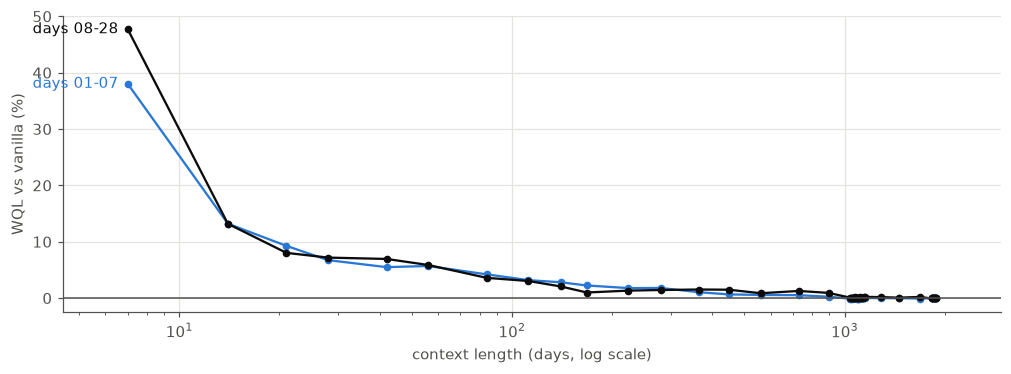

segment,best_context,WQL,within 1% of best
str,i64,f64,list[i64]
"""days 01-07""",1099,0.545072,"[448, 560, … 1885]"
"""days 08-28""",1829,0.562194,"[560, 896, … 1885]"


In [8]:
coarse_winners = winners(coarse_segment)["best_context"].to_list()
FINE_GRID = sorted({
    length
    for winner in coarse_winners
    for length in range(max(FINE_STEP, winner - FINE_HALF_WIDTH), min(MAX_HISTORY, winner + FINE_HALF_WIDTH) + 1, FINE_STEP)
} - set(COARSE_GRID))
print(f"Fine grid ({len(FINE_GRID)} new lengths): {FINE_GRID}")

fine_bucket, fine_segment, fine_overall = sweep(FINE_GRID)
all_bucket = pl.concat([coarse_bucket, fine_bucket])
all_segment = pl.concat([coarse_segment, fine_segment])
all_overall = pl.concat([coarse_overall, fine_overall])

plot_segments(all_segment)
plt.show()
choice = winners(all_segment)
choice

Does the choice depend on the metric? The same rule with WMAPE (the point-forecast headline) instead of WQL.

In [9]:
winners(all_segment, metric="WMAPE")

segment,best_context,WMAPE,within 1% of best
str,i64,f64,list[i64]
"""days 01-07""",1288,68.796575,"[448, 560, … 1885]"
"""days 08-28""",1829,71.085181,"[168, 1036, … 1885]"


## 3. The two winners and vanilla, by horizon bucket

days 1-7: 1099 days of context; days 8-28: 1829; best single length overall: 1829


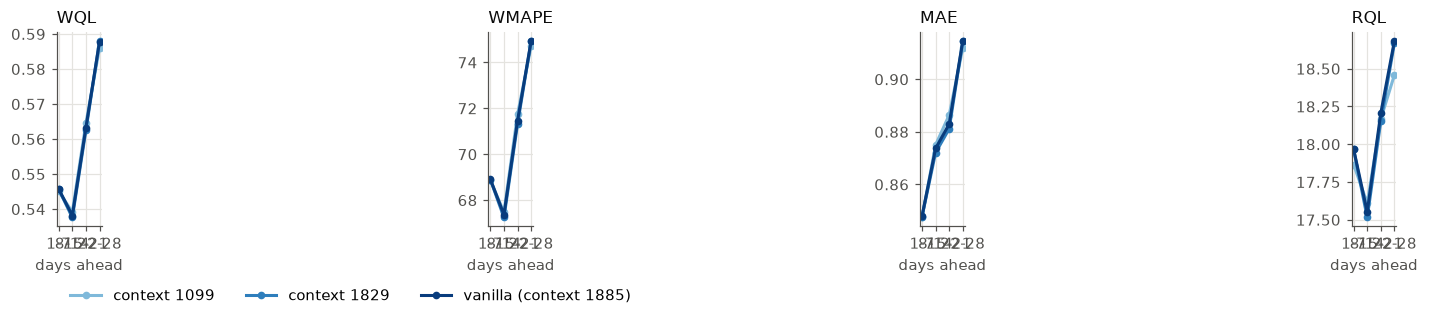

In [10]:
EARLY_CONTEXT = choice.filter(pl.col("segment") == "days 01-07")["best_context"][0]
LATE_CONTEXT = choice.filter(pl.col("segment") == "days 08-28")["best_context"][0]
BEST_SINGLE = all_overall.sort(SELECTION_METRIC)["context_length"][0]
print(f"days 1-7: {EARLY_CONTEXT} days of context; days 8-28: {LATE_CONTEXT}; best single length overall: {BEST_SINGLE}")

shortlist = {f"context {EARLY_CONTEXT}": EARLY_CONTEXT, f"context {LATE_CONTEXT}": LATE_CONTEXT,
             f"vanilla (context {MAX_HISTORY})": MAX_HISTORY}
ramp = plt.get_cmap("Blues")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for (label, length), shade in zip(shortlist.items(), np.linspace(0.45, 0.95, len(shortlist))):
    rows = all_bucket.filter(pl.col("context_length") == length).sort("horizon_bucket")
    for ax, metric in zip(axes, ["WQL", "WMAPE", "MAE", "RQL"]):
        ax.plot(range(rows.height), rows[metric].to_numpy(), color=ramp(shade), marker="o", markersize=4, label=label)
for ax, metric in zip(axes, ["WQL", "WMAPE", "MAE", "RQL"]):
    ax.set_title(metric, loc="left")
    ax.set_xticks(range(4))
    ax.set_xticklabels(["1-7", "8-14", "15-21", "22-28"])
    ax.set_xlabel("days ahead")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.25), ncol=3)
fig.tight_layout()
plt.show()

## 4. Stitch

Days 1–7 from the early winner, days 8–28 from the late winner. If both winners are the same length, the
stitch is just that single model.

In [11]:
stitched = stitch(run_context(EARLY_CONTEXT), run_context(LATE_CONTEXT), EARLY_LAST_DAY)
candidates = {
    "vanilla": run_context(MAX_HISTORY),
    f"best single length ({BEST_SINGLE})": run_context(BEST_SINGLE),
    f"stitch {EARLY_CONTEXT} -> {LATE_CONTEXT}": stitched,
}
scored = {name: join_truth(table, truth, validation_roster) for name, table in candidates.items()}
compare(scored, reference="vanilla").select(["model", "n_series"] + METRICS + [f"{m}_change_%" for m in METRICS])

model,n_series,MAE,WMAPE,P90,WQL,RQL,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""vanilla""",473,0.879784,70.61731,2.212585,0.558412,18.094016,0.0,0.0,0.0,0.0,0.0
"""best single length (1829)""",473,0.878884,70.545083,2.207293,0.558107,18.067774,-0.102279,-0.102279,-0.239191,-0.054577,-0.145035
"""stitch 1099 -> 1829""",473,0.878805,70.538709,2.203492,0.557966,18.043145,-0.111305,-0.111305,-0.411007,-0.079884,-0.281153


In [12]:
compare(scored, by="horizon_bucket", reference="vanilla").select(
    ["model", "horizon_bucket"] + [f"{m}_change_%" for m in ["WQL", "WMAPE", "MAE"]]
).sort("model", "horizon_bucket")

model,horizon_bucket,WQL_change_%,WMAPE_change_%,MAE_change_%
str,str,f64,f64,f64
"""best single length (1829)""","""days 01-07""",-0.015076,-0.014028,-0.014028
"""best single length (1829)""","""days 08-14""",-0.104643,-0.182713,-0.182713
"""best single length (1829)""","""days 15-21""",-0.140324,-0.206456,-0.206456
"""best single length (1829)""","""days 22-28""",0.04035,-0.006672,-0.006672
"""stitch 1099 -> 1829""","""days 01-07""",-0.119953,-0.051491,-0.051491
…,…,…,…,…
"""stitch 1099 -> 1829""","""days 22-28""",0.04035,-0.006672,-0.006672
"""vanilla""","""days 01-07""",0.0,0.0,0.0
"""vanilla""","""days 08-14""",0.0,0.0,0.0


**How much to trust this.** The choice is made among a few dozen lengths on a single window of ~470 series,
so the winner's margin is partly luck: the `within 1% of best` column above shows how flat the optimum is.
The test window of notebook 08, never used here, is the honest check.

Save the choice for notebook 08.

In [13]:
choice_path = ARTIFACTS_DIR / f"context_choice_{NAME}.json"
choice_record = {
    "early_context": int(EARLY_CONTEXT),
    "late_context": int(LATE_CONTEXT),
    "early_last_day": EARLY_LAST_DAY,
    "best_single_context": int(BEST_SINGLE),
    "vanilla_context": int(MAX_HISTORY),
    "selection_metric": SELECTION_METRIC,
    "selected_on": f"validation window, origin {VALIDATION_ORIGIN}",
}
choice_path.write_text(json.dumps(choice_record, indent=2))
print(f"Saved to {choice_path.name}")
choice_record

Saved to context_choice_n500_seed42.json


{'early_context': 1099,
 'late_context': 1829,
 'early_last_day': 7,
 'best_single_context': 1829,
 'vanilla_context': 1885,
 'selection_metric': 'WQL',
 'selected_on': 'validation window, origin 2016-03-27'}

## Notes

*Your observations here.*